# 1. As contas do texto conferem?

O texto ["O Juro é negativo após 2008"](https://amoedo.substack.com/p/o-juro-e-negativo-apos-2008), do
Trezoitão, compara em vários períodos quanto renderam a **Selic**, o **Ibovespa** e o **ouro** com quanto cresceu o
**M2**, a soma do dinheiro em circulação com os depósitos e títulos emitidos pelos bancos. A tese: antes de 2008 os
investimentos ganhavam do M2; depois, não ganham mais.

Antes de discutir se essa comparação faz sentido, este notebook confere a aritmética. São 36 números citados no
texto, transcritos em `data/manual/afirmacoes.csv` com o trecho de onde cada um saiu. Aqui eles são refeitos com
os dados do Banco Central, da B3, do Federal Reserve e do Banco Mundial.

Os períodos seguem a convenção do texto: "de jan/2008 a jan/2018" vai da abertura de janeiro de 2008 à abertura de
janeiro de 2018, ou seja, do fim de dezembro de 2007 ao fim de dezembro de 2017.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from juro_negativo import analise, estilo
from juro_negativo.caminhos import TRATADOS
from juro_negativo.estilo import pct
from juro_negativo.fontes import afirmacoes

estilo.aplicar()

brasil = pd.read_parquet(TRATADOS / "brasil.parquet")
eua = pd.read_parquet(TRATADOS / "eua.parquet")
niveis = analise.niveis_do_brasil(brasil)
niveis_eua = analise.niveis_dos_eua(eua)

conferidas = analise.conferir(afirmacoes.ler(), {"Brasil": niveis, "Estados Unidos": niveis_eua})
TOLERANCIA = 0.05  # até 5% de diferença no valor final conta como "bate"
conferidas["bate"] = conferidas["erro_relativo"].abs() <= TOLERANCIA
print(f"Dados do Brasil até {niveis.index[-1]:%m/%Y}; números conferidos: {len(conferidas)}")

Dados do Brasil até 08/2026; números conferidos: 36


## Número por número

`citado` é o que está no texto; `refeito`, o que sai dos dados. A diferença compara os valores finais: um
investimento que o texto diz ter multiplicado por 26,48 e que nos dados multiplicou por 28,18 tem diferença de
6%.

In [2]:
def periodo(linha):
    return f"{linha.inicio:%m/%Y} a {linha.fim:%m/%Y}"


tabela = pd.DataFrame(
    {
        "país": conferidas["pais"],
        "período": conferidas.apply(periodo, axis=1),
        "série": conferidas["serie"],
        "citado": conferidas["variacao_citada"].map(lambda v: pct(v, 1)),
        "refeito": conferidas["variacao_calculada"].map(lambda v: pct(v, 1)),
        "diferença": conferidas["erro_relativo"].map(lambda v: pct(v, 1, sinal=True)),
        "bate": conferidas["bate"].map({True: "sim", False: "não"}),
    }
)
tabela

,país,período,série,citado,refeito,diferença,bate
0,Brasil,01/1995 a 09/2022,ouro,"2.548,0%","2.717,6%","+6,4%",não
1,Brasil,01/1995 a 09/2022,ibovespa,"2.416,0%","2.415,5%","−0,0%",sim
2,Brasil,01/1995 a 09/2022,m1,"3.148,0%","2.699,8%","−13,8%",não
3,Brasil,01/1995 a 09/2022,m2,"3.298,0%","3.472,4%","+5,1%",não
4,Brasil,01/1995 a 10/2022,cdi,"5.039,0%","5.042,4%","+0,1%",sim
5,Brasil,01/1995 a 07/2008,cdi,"1.376,0%","1.376,1%","+0,0%",sim
6,Brasil,07/2008 a 10/2022,cdi,"248,0%","248,4%","+0,1%",sim
7,Brasil,01/1998 a 01/2008,selic,"483,6%","483,3%","−0,0%",sim
8,Brasil,01/1998 a 01/2008,ibovespa,"626,0%","526,5%","−13,7%",não
9,Brasil,01/1998 a 01/2008,ouro,"365,8%","345,6%","−4,3%",sim


## Quantos batem

**21 dos 36 números** batem com diferença menor que 5%, e 27 com menos de 10%. Os de Selic e CDI batem na
vírgula: a fonte é a mesma (Banco Central) e a conta é a mesma. O Ibovespa de ponta a ponta (1995 a 2022) também:
4.353 pontos na abertura de 1995 e 109.523 na de setembro de 2022, exatamente os valores do texto.

O ouro é a série que mais difere, por um motivo conhecido: o texto usou cotações de um dia e este projeto usa a
média do mês (a série mensal do Banco Mundial, convertida pelo dólar médio).

In [3]:
resumo = conferidas.groupby("serie").agg(
    números=("bate", "size"),
    batem=("bate", "sum"),
    diferença_mediana=("erro_relativo", lambda erros: pct(erros.abs().median(), 1)),
)
print(f"Batem: {conferidas['bate'].sum()} de {len(conferidas)}")
print(f"Com menos de 10% de diferença: {(conferidas['erro_relativo'].abs() <= 0.10).sum()}")
resumo

Batem: 21 de 36
Com menos de 10% de diferença: 27


,números,batem,diferença_mediana
serie,,,
cdi,3,3,"0,1%"
ibovespa,6,4,"3,5%"
m1,4,2,"4,6%"
m2,6,4,"2,4%"
ouro,9,3,"6,9%"
selic,5,4,"0,0%"
sp500,3,1,"20,4%"


## Os que não batem

Três tipos de erro aparecem:

1. **Digitação.** O Ibovespa de jan/2008 a jan/2018 aparece como 119,6%; o número certo é 19,6%. De jan/1998 a
   jan/2008, 626% no texto e 526,5% nos dados. Nos dois casos sobram exatamente 100 pontos, como se o valor final
   (em % do inicial) tivesse entrado no lugar da variação.
2. **Datas diferentes das anunciadas.** Na pandemia (jan/2020 a set/2022) o texto dá 7,3% para a Selic e 39,2%
   para o M2; os dados dão 15,6% e 54,2%. Nos Estados Unidos, os 40,5% do S&P 500 "de jan/2018 a jan/2022" ficam
   longe dos 75,5% do período anunciado e perto do que o índice rendeu até outubro de 2022, a data do texto (44,5%).
3. **Preço com e sem dividendos.** O S&P 500 de 2008 a 2018 aparece com 126,2%, que é o retorno com dividendos
   (122,6% aqui); nos outros dois períodos o texto usa o índice de preço.

O erro mais sério, o do M1 dos Estados Unidos, não é de conta e sim de série: fica para o notebook 4.

In [4]:
fora = conferidas[conferidas["erro_relativo"].abs() > 0.10]
tabela.loc[fora.index]

,país,período,série,citado,refeito,diferença,bate
2,Brasil,01/1995 a 09/2022,m1,"3.148,0%","2.699,8%","−13,8%",não
8,Brasil,01/1998 a 01/2008,ibovespa,"626,0%","526,5%","−13,7%",não
12,Brasil,01/2008 a 01/2018,ibovespa,"119,6%","19,6%","−45,5%",não
13,Brasil,01/2008 a 01/2018,ouro,"161,7%","190,1%","+10,9%",não
26,Brasil,01/2020 a 09/2022,m2,"39,2%","54,2%","+10,8%",não
28,Estados Unidos,01/1998 a 01/2008,ouro,"232,6%","177,9%","−16,5%",não
30,Estados Unidos,01/2008 a 01/2018,sp500,"126,2%","80,1%","−20,4%",não
33,Estados Unidos,01/2018 a 01/2022,sp500,"40,5%","75,5%","+24,9%",não
34,Estados Unidos,01/2018 a 01/2022,ouro,"18,5%","41,6%","+19,5%",não


In [5]:
# O S&P 500 e o ouro em dólar "de jan/2018 a jan/2022", medidos até a data do texto (outubro de 2022).
ate_o_texto = analise.variacao(niveis_eua, "2018-01", "2022-10")
print(f"S&P 500 (preço) de jan/2018 a out/2022: {pct(ate_o_texto['sp500'], 1)}  (texto: 40,5%)")
print(
    f"S&P 500 com dividendos de jan/2008 a jan/2018: {pct(analise.variacao(niveis_eua, '2008-01', '2018-01')['sp500_total'], 1)}  (texto: 126,2%)"
)

S&P 500 (preço) de jan/2018 a out/2022: 44,5%  (texto: 40,5%)
S&P 500 com dividendos de jan/2008 a jan/2018: 122,6%  (texto: 126,2%)


## As correções mudam alguma conclusão?

O que importa no texto é a ordem: em cada período, quem rendeu mais que o M2. Refazendo os números, a ordem é a
mesma em 14 das 15 comparações do Brasil. A exceção é o ouro na pandemia, que no texto empata com o M2 (39,4%
contra 39,2%) e nos dados perde por pouco (49,4% contra 54,2%).

Ou seja: os erros de digitação e de data não ajudam o argumento. Corrigidos, eles o deixam igual ou até mais
forte (o Ibovespa de 2008 a 2018 rendeu muito menos do que o texto diz).

In [6]:
JANELAS = ["1998 a 2008", "2008 a 2018", "2000 a 2010", "2010 a 2020", "Pandemia"]
linhas = []
for janela in JANELAS:
    numeros = conferidas[(conferidas["pais"] == "Brasil") & (conferidas["grupo"] == janela)].set_index("serie")
    m2 = numeros.loc["m2"]
    for ativo in ["selic", "ibovespa", "ouro"]:
        linhas.append(
            {
                "período": janela,
                "investimento": ativo,
                "ganhou do M2 (texto)": numeros.loc[ativo, "variacao_citada"] > m2["variacao_citada"],
                "ganhou do M2 (refeito)": numeros.loc[ativo, "variacao_calculada"] > m2["variacao_calculada"],
            }
        )
ordem = pd.DataFrame(linhas)
print(f"Mesma conclusão em {(ordem.iloc[:, 2] == ordem.iloc[:, 3]).sum()} de {len(ordem)} comparações")
ordem.replace({True: "sim", False: "não"}).set_index(["período", "investimento"])

Mesma conclusão em 14 de 15 comparações


ganhou do M2 (texto) ganhou do M2 (refeito)
período     investimento                                            
1998 a 2008 selic                         sim                    sim
            ibovespa                      sim                    sim
            ouro                          sim                    sim
2008 a 2018 selic                         não                    não
            ibovespa                      não                    não
            ouro                          não                    não
2000 a 2010 selic                         sim                    sim
            ibovespa                      não                    não
            ouro                          não                    não
2010 a 2020 selic                         não                    não
            ibovespa                      não                    não
            ouro                          sim                    sim
Pandemia    selic                         não                    não
            ibovespa                      não                    não
            ouro                          sim                    não

## O argumento em um gráfico

Com os números refeitos, os dois períodos de dez anos que o texto põe lado a lado. De 1998 a 2008, Selic,
Ibovespa e ouro renderam mais do que o M2 cresceu. De 2008 a 2018, nenhum dos três.

A última barra de cada painel é a que o texto deixa de fora: a inflação de preços (IPCA). Ela ficou muito abaixo
do M2 nos dois períodos, e a Selic ganhou dela com folga nos dois.

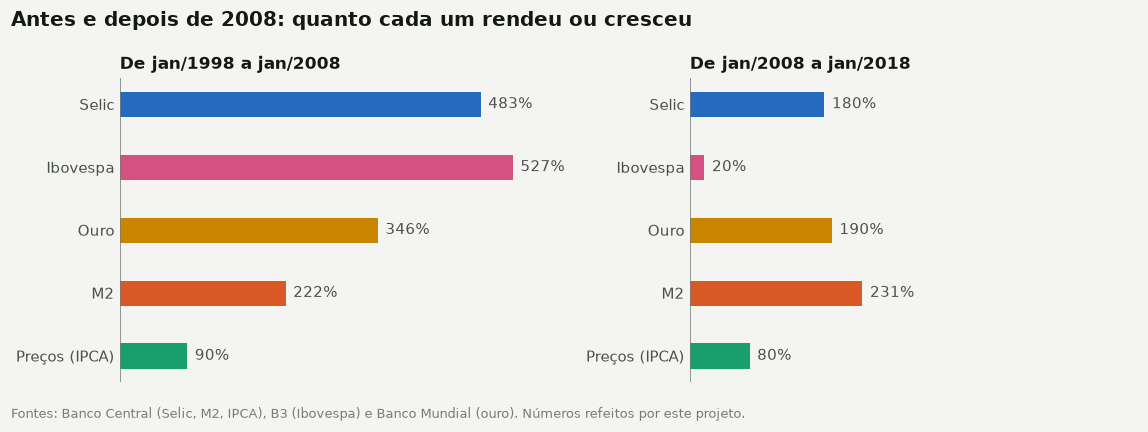

In [7]:
SERIES = {"selic": "Selic", "ibovespa": "Ibovespa", "ouro": "Ouro", "m2": "M2", "ipca": "Preços (IPCA)"}
PERIODOS = [("1998-01", "2008-01"), ("2008-01", "2018-01")]

fig, eixos = plt.subplots(1, 2, figsize=(10.5, 3.6), sharex=True)
for ax, (inicio, fim) in zip(eixos, PERIODOS):
    variacoes = analise.variacao(niveis, inicio, fim)[list(SERIES)].rename(SERIES)
    estilo.barras(ax, variacoes, [estilo.cor(serie) for serie in SERIES], lambda v: pct(v))
    ax.set_title(f"De jan/{inicio[:4]} a jan/{fim[:4]}", loc="left", fontsize=11, fontweight="bold")
fig.suptitle(
    "Antes e depois de 2008: quanto cada um rendeu ou cresceu", x=0.01, ha="left", fontsize=13, fontweight="bold"
)
fig.tight_layout()
estilo.fonte(
    fig,
    "Fontes: Banco Central (Selic, M2, IPCA), B3 (Ibovespa) e Banco Mundial (ouro). Números refeitos por este projeto.",
)
plt.show()

## O CDI "em duas metades"

O texto divide 1995 a 2022 ao meio: na primeira metade o CDI multiplicou o dinheiro por 14,76; na segunda, por
3,48, "ordem de grandeza a menos". Os dois números conferem. Mas a comparação é entre valores nominais de duas
épocas com inflações muito diferentes.

Descontando o IPCA, o CDI multiplicou o poder de compra por 5,3 na primeira metade (13,1% ao ano acima da
inflação, um dos juros reais mais altos do mundo na época) e por 1,55 na segunda (3,1% ao ano). O juro real caiu
muito, e isso é verdade. Só não ficou negativo.

In [8]:
linhas = []
for inicio, fim in [("1995-01", "2008-07"), ("2008-07", "2022-10")]:
    v = analise.variacao(niveis, inicio, fim)
    meses = analise.meses_entre(inicio, fim)
    real = analise.descontar(v["cdi"], v["ipca"])
    linhas.append(
        {
            "período": f"{inicio[5:]}/{inicio[:4]} a {fim[5:]}/{fim[:4]}",
            "CDI (vezes)": estilo.br(1 + v["cdi"], 2),
            "IPCA (vezes)": estilo.br(1 + v["ipca"], 2),
            "CDI acima da inflação (vezes)": estilo.br(1 + real, 2),
            "CDI ao ano": pct(analise.anualizar(v["cdi"], meses), 1),
            "IPCA ao ano": pct(analise.anualizar(v["ipca"], meses), 1),
            "juro real ao ano": pct(analise.anualizar(real, meses), 1),
        }
    )
pd.DataFrame(linhas).set_index("período")

,CDI (vezes),IPCA (vezes),CDI acima da inflação (vezes),CDI ao ano,IPCA ao ano,juro real ao ano
período,,,,,,
01/1995 a 07/2008,"14,76","2,79","5,30","22,1%","7,9%","13,1%"
07/2008 a 10/2022,"3,48","2,25","1,55","9,2%","5,9%","3,1%"


## O que fica deste notebook

1. **As contas do texto, no essencial, estão certas.** 21 dos 36 números batem com menos de 5% de diferença, e os
   de juros batem na vírgula.
2. **Os erros que existem não mudam as comparações do Brasil.** São de digitação (o Ibovespa de 119,6% que é
   19,6%) e de data, e corrigi-los não favorece nem prejudica a tese.
3. **A Selic e o Ibovespa realmente renderam menos do que o M2 cresceu depois de 2008**, e mais do que ele antes.
   Esse fato está de pé.
4. **A dúvida que sobra é de régua, não de conta.** No mesmo período em que perdeu do M2, a Selic ganhou da
   inflação de preços. O próximo notebook pergunta qual das duas réguas mede o que o texto diz medir.